# Used Car Market Segmentation
## Unsupervised Machine Learning Portfolio Project

**Objective:** Segment used-car inventory into interpretable market groups with K-Means.

**Business question:** Can cars be grouped by age, price, usage, efficiency, engine, power, and capacity to support inventory positioning and marketing?

**Workflow:** Cleaning → transformation/scaling → K selection → K-Means → cluster profiling → business interpretation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
df = pd.read_csv("Car_details_v3.csv")
print("Shape:", df.shape)
df.head()

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-tyxdt49q because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


## 1. Data Cleaning & Feature Engineering

In [2]:
data = df.copy()
data["brand"] = data["name"].str.split().str[0]
for col in ["mileage","engine","max_power"]:
    data[col+"_num"] = pd.to_numeric(
        data[col].astype(str).str.extract(r"([-+]?\d*\.?\d+)")[0], errors="coerce")
print("Missing values after extraction:")
print(data[["mileage_num","engine_num","max_power_num","seats"]].isna().sum())

Missing values after extraction:
mileage_num      221
engine_num       221
max_power_num    216
seats            221
dtype: int64


## 2. Prepare Clustering Features

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

features=["year","selling_price","km_driven","seats","mileage_num","engine_num","max_power_num"]
X=data[features].copy()
X["selling_price"]=np.log1p(X["selling_price"])
X["km_driven"]=np.log1p(X["km_driven"])

imputer=SimpleImputer(strategy="median")
scaler=StandardScaler()
X_scaled=scaler.fit_transform(imputer.fit_transform(X))
print("Clustering matrix:",X_scaled.shape)

Clustering matrix: (8128, 7)


## 3. Select K

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rows=[]
for k in range(2,7):
    model=KMeans(n_clusters=k,random_state=42,n_init=20)
    labels=model.fit_predict(X_scaled)
    rows.append([k,silhouette_score(X_scaled,labels),model.inertia_])
selection=pd.DataFrame(rows,columns=["k","Silhouette","Inertia"])
selection

,k,Silhouette,Inertia
0,2,0.398578,39319.877613
1,3,0.277756,30590.032370
2,4,0.303286,24876.146438
3,5,0.263573,21756.396736
4,6,0.236210,19975.247224


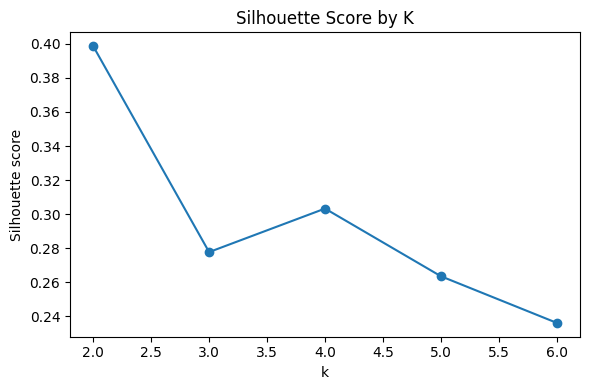

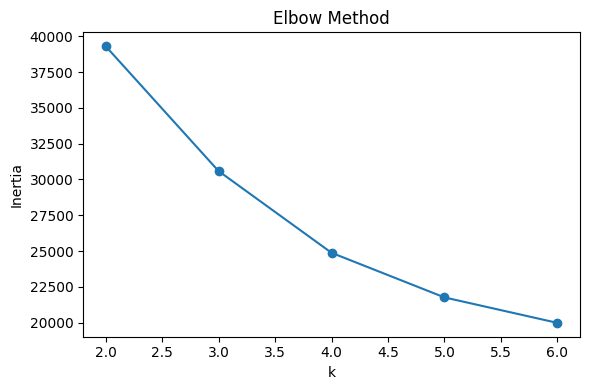

In [5]:
plt.figure(figsize=(6,4))
plt.plot(selection.k,selection.Silhouette,marker="o")
plt.title("Silhouette Score by K"); plt.xlabel("k"); plt.ylabel("Silhouette score")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6,4))
plt.plot(selection.k,selection.Inertia,marker="o")
plt.title("Elbow Method"); plt.xlabel("k"); plt.ylabel("Inertia")
plt.tight_layout(); plt.show()

### Choice of K
`k=2` has the highest silhouette score (~0.399), but it creates segments that are too broad for the intended business use. We select **k=4** as a deliberate interpretability trade-off: its silhouette score remains reasonable (~0.303), while four groups provide richer inventory profiles.


## 4. Build and Profile Four Segments

In [6]:
kmeans=KMeans(n_clusters=4,random_state=42,n_init=20)
data["cluster"]=kmeans.fit_predict(X_scaled)

profile=data.groupby("cluster").agg(
 Vehicles=("name","size"),
 Median_Price=("selling_price","median"),
 Median_Year=("year","median"),
 Median_KM=("km_driven","median"),
 Median_Mileage=("mileage_num","median"),
 Median_Engine=("engine_num","median"),
 Median_Power=("max_power_num","median"),
 Median_Seats=("seats","median")
).round(2)
profile

,Vehicles,Median_Price,Median_Year,Median_KM,Median_Mileage,Median_Engine,Median_Power,Median_Seats
cluster,,,,,,,,
0,639,2475000.0,2018.0,25000.0,16.78,1999.0,177.00,5.0
1,2524,200000.0,2011.0,89161.0,19.00,1248.0,70.00,5.0
2,3805,550000.0,2016.0,40000.0,21.90,1199.0,81.86,5.0
3,1160,600000.0,2013.0,100000.0,14.00,2393.0,103.25,7.0


## 5. Visualize Segments

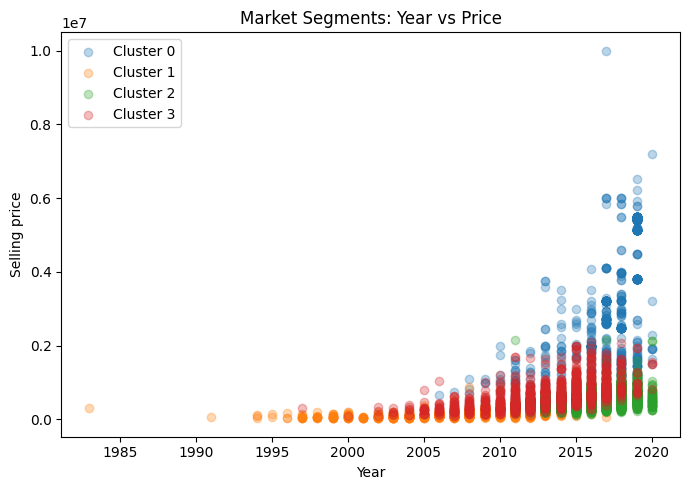

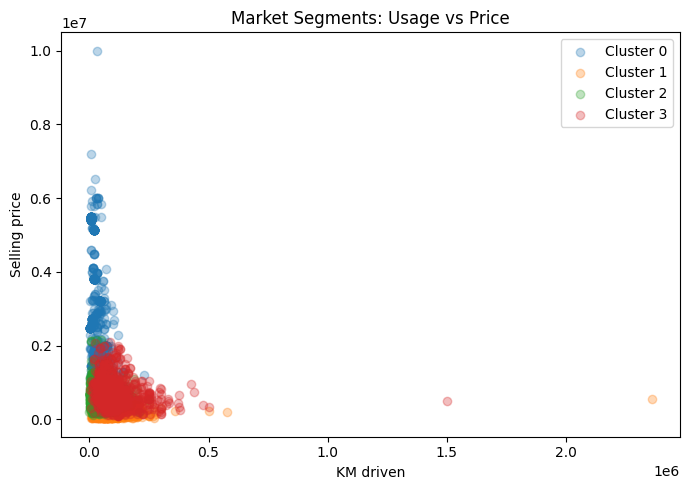

In [7]:
plt.figure(figsize=(7,5))
for c in sorted(data.cluster.unique()):
    s=data[data.cluster==c]
    plt.scatter(s.year,s.selling_price,alpha=.3,label=f"Cluster {c}")
plt.title("Market Segments: Year vs Price"); plt.xlabel("Year"); plt.ylabel("Selling price")
plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(7,5))
for c in sorted(data.cluster.unique()):
    s=data[data.cluster==c]
    plt.scatter(s.km_driven,s.selling_price,alpha=.3,label=f"Cluster {c}")
plt.title("Market Segments: Usage vs Price"); plt.xlabel("KM driven"); plt.ylabel("Selling price")
plt.legend(); plt.tight_layout(); plt.show()

## 6. Segment Interpretation & Recommendations

The reproducible four-cluster solution produces:

- **Cluster 0 — Premium / newer high-performance:** 639 cars; median price ≈ 2.48M, year 2018, ~25K km, highest median power.
- **Cluster 1 — Older budget:** 2,524 cars; median price ≈ 200K, year 2011, ~89K km.
- **Cluster 2 — Newer mainstream efficient:** 3,805 cars; median price ≈ 550K, year 2016, ~40K km; largest segment.
- **Cluster 3 — Larger / utility-oriented:** 1,160 cars; median 7 seats, larger engines, ~100K km, median price ≈ 600K.

### Business recommendations
- Position Cluster 0 around premium/performance.
- Target Cluster 1 to price-sensitive shoppers.
- Treat Cluster 2 as core mainstream inventory.
- Market Cluster 3 around space/capacity, with extra emphasis on maintenance and condition.

### Limitations
K-Means depends on feature selection and scaling. Segment names are analyst interpretations, not ground-truth labels. Geography, condition, accident history, and demand are not included.
